# Stage 4 exploration — `songs_final.csv`
Genre coverage, distribution, and gaps for the songs matched so far.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/songs_final.csv")
print(f"{len(df)} songs matched so far (full catalog is 1164)")
df.head()

1143 songs matched so far (full catalog is 1164)


,line_no,song,artist,year,genre,subgenre,duration,bpm,popularity,liked
0,1,24 K Magic,Bruno Mars,2016,Pop,NaN,225983,NaN,NaN,NaN
1,2,25 Horas Al Dia,Juan Luis Guerra,2013,Merengue,NaN,234795,NaN,NaN,NaN
2,3,30 Segundos,Marisol,2010,NaN,NaN,280189,NaN,NaN,NaN
3,4,90's Be My Lover,La Bouche,1996,Pop,NaN,240266,NaN,NaN,NaN
4,5,90's Pump Up the Jum,Technotronic,1989,Electronic,NaN,320306,NaN,NaN,NaN


## Genre coverage

In [2]:
n_missing = df["genre"].isna().sum()
print(f"{len(df) - n_missing}/{len(df)} songs have a resolved genre ({n_missing} missing)")

828/1143 songs have a resolved genre (315 missing)


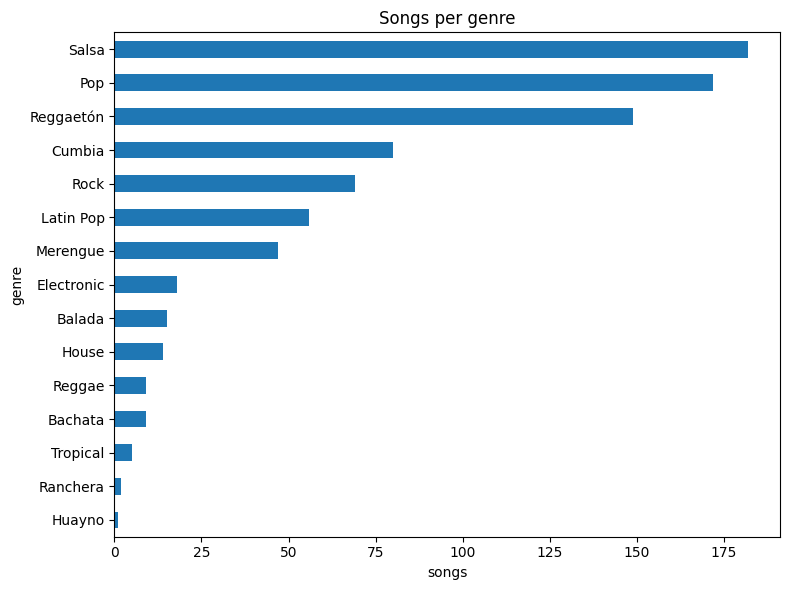

In [3]:
genre_counts = df["genre"].value_counts()
genre_counts.plot(kind="barh", figsize=(8, 6), title="Songs per genre")
plt.gca().invert_yaxis()
plt.xlabel("songs")
plt.tight_layout()
plt.show()

## Songs missing a genre
For triage — usually garbled artist names from PDF/OCR cleanup (see `data/dictionaries/artist_aliases.json`).

In [4]:
missing_genre = df[df["genre"].isna()][["line_no", "song", "artist"]]
missing_genre.to_csv("../data/processed/songs_missing_genre.csv", index=False)
missing_genre

,line_no,song,artist
2,3,30 Segundos,Marisol
13,14,A Veces Me Parece,Ariztia
19,20,Agachadita Mix,NaN
23,24,Ahí Na Ma,Frankie Vasquez
32,33,All Time Rock And Roll,NaN
...,...,...,...
1128,1129,When You Say Nothing At All,NaN
1130,1131,Whine Up,NaN
1131,1132,Whith Or Whitout You,Jhonny Sky
1139,1140,Y Que Tal Si Salimos Todos a Bailar,NaN


## Songs that did not match Spotify
Separate from genre gaps: these never got a Spotify track at all, or matched with low confidence.
Source: `data/dictionaries/artist_aliases.json` fixes usually help here too.

In [5]:
meta = pd.read_csv("../data/processed/songs_metadata.csv")
no_match = meta[meta["track_id"].isna()]
low_conf = meta[meta["track_id"].notna() & meta["low_confidence_match"]]
print(f"{len(no_match)} songs with no Spotify match at all")
print(f"{len(low_conf)} songs matched but flagged low_confidence_match")

0 songs with no Spotify match at all
373 songs matched but flagged low_confidence_match


### No match at all

In [6]:
no_match = no_match[["line_no", "song_clean", "artist_corrected"]]
no_match.to_csv("../data/processed/songs_no_spotify_match.csv", index=False)
no_match

,line_no,song_clean,artist_corrected


### Low-confidence matches (worth a manual check)

In [7]:
low_conf = low_conf[["line_no", "song_clean", "artist_corrected", "official_artist", "match_score"]].sort_values("match_score")
low_conf.to_csv("../data/processed/songs_low_confidence_match.csv", index=False)
low_conf

,line_no,song_clean,artist_corrected,official_artist,match_score
1066,1067,Twist de Rully,Rully Rendo,Cyrcus Music,19.0
461,462,Huaynos Varios,NaN,Various Artists,20.6
1139,1140,Y Que Tal Si Salimos Todos a Bailar,NaN,Adolescent's Orquesta,22.5
455,456,Hora Hip Hop 90's,NaN,Angelina,22.9
39,40,Amargura,Karol G,KAROL G,24.6
...,...,...,...,...,...
345,346,El Taki Taki,Ilegales,Ilegales,69.3
281,282,Directo Al Corazon,La Verdad,La verdad del norte,69.5
752,753,Oh Daddy,Nati Natasha,NATTI NATASHA,69.6
773,774,Papacito,Karol G,KAROL G,69.6


## Songs per decade

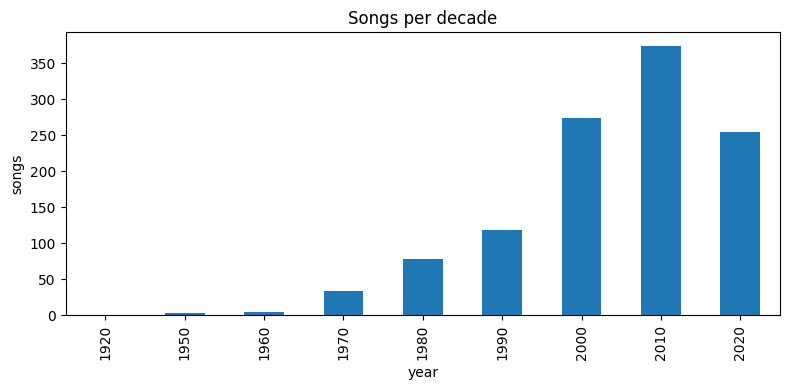

In [8]:
decade = (df["year"].dropna() // 10 * 10).astype(int)
decade.value_counts().sort_index().plot(kind="bar", figsize=(8, 4), title="Songs per decade")
plt.ylabel("songs")
plt.tight_layout()
plt.show()

## Genre by decade

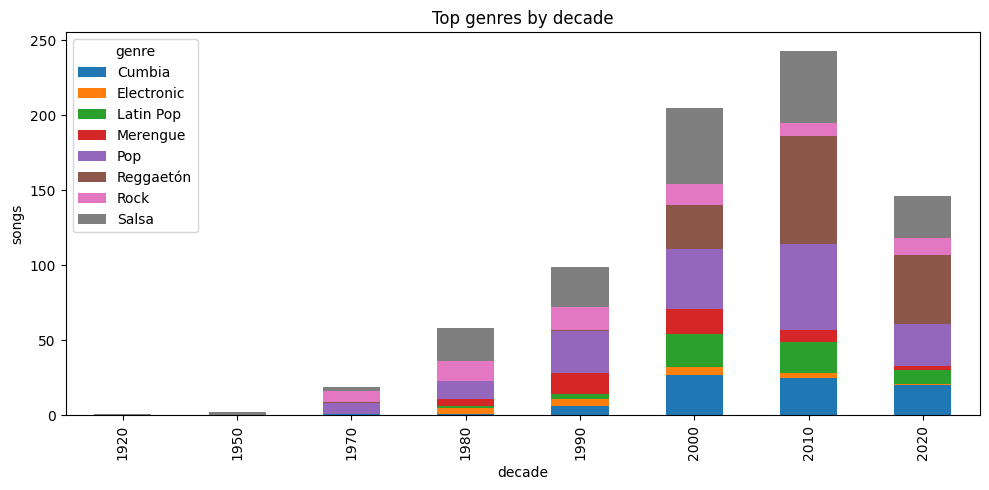

In [9]:
top_genres = genre_counts.head(8).index
pivot = df.assign(decade=decade).query("genre in @top_genres").pivot_table(
    index="decade", columns="genre", values="song", aggfunc="count", fill_value=0
)
pivot.plot(kind="bar", stacked=True, figsize=(10, 5), title="Top genres by decade")
plt.ylabel("songs")
plt.tight_layout()
plt.show()